# Assignment 4: Machine Learning and Neural Networks
**Студент:** Балтабаев Кайсар
**Группа:** AAI-2603M


| Task | Что делаем | Библиотека |
|---|---|---|
| 1 | Классификация Iris: Decision Tree vs Logistic Regression vs KNN | scikit-learn |
| 2 | Важность признаков, матрица ошибок, влияние гиперпараметров | scikit-learn |
| 3 | Перцептрон с 1 скрытым слоем: ReLU vs Sigmoid vs Tanh | PyTorch |
| 4 | MLP на MNIST: влияние числа эпох и batch size | PyTorch |

In [159]:
# config

RANDOM_STATE = 42          # единый сид для sklearn / numpy / torch

# перцептрон
T3_CFG = dict(
    lr=1e-3, batch_size=32, max_epochs=300, hidden_dim=16,
    weight_decay=1e-4, patience=20,          # ранняя остановка: 20 эпох без улучшения valid loss
    activations=["relu", "sigmoid", "tanh"],
    stability_seeds=[0, 1, 2, 3, 4],         # повторные запуски для оценки устойчивости
)

# MLP на MNIST
T4_CFG = dict(
    hidden=[256, 128, 64], lr=1e-3, val_size=6000,
    epochs_grid=[5, 10, 20], batch_grid=[32, 64, 128],
)

In [160]:
import time, random, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score)

import torch
import torch.nn as nn

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(RANDOM_STATE)
torch.set_num_threads(max(1, os.cpu_count() or 1))
os.makedirs("results", exist_ok=True)
plt.rcParams["figure.dpi"] = 110
print("torch", torch.__version__)

torch 2.15.0


---
# Task 1. Классификация на датасете Iris

**Идея:** есть 150 цветков ириса, у каждого 4 измерения (длина/ширина чашелистика *sepal* и лепестка *petal*).
Нужно по этим 4 числам определить один из 3 видов: *setosa, versicolor, virginica*.
Сравниваем три классических алгоритма:

- **Decision Tree** - набор вопросов «если petal length < 2.45, то …». Масштаб признаков ему не важен.
- **Logistic Regression** - линейная модель: считает взвешенную сумму признаков и превращает её в вероятность. Границы между классами - прямые (гиперплоскости).
- **KNN** - «скажи, кто твои соседи»: класс определяется голосованием k ближайших точек. Работает на расстояниях → **обязательно масштабирование**, иначе признак с большими числами доминирует.

## 1.1–1.2 Загрузка и первичный анализ

In [161]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
class_names = list(iris.target_names)

print("X shape:", X.shape, "| y shape:", y.shape)
print("Признаки:", feature_names)
print("Классы:", class_names)
print("Баланс классов (np.bincount):", np.bincount(y))
pd.DataFrame(X, columns=feature_names).describe().round(2)

X shape: (150, 4) | y shape: (150,)
Признаки: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Классы: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Баланс классов (np.bincount): [50 50 50]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00000,150.00000,150.00000,150.00000
mean,5.84000,3.06000,3.76000,1.20000
std,0.83000,0.44000,1.77000,0.76000
min,4.30000,2.00000,1.00000,0.10000
25%,5.10000,2.80000,1.60000,0.30000
50%,5.80000,3.00000,4.35000,1.30000
75%,6.40000,3.30000,5.10000,1.80000
max,7.90000,4.40000,6.90000,2.50000


note: bincount выдал [50 50 50], это значит что классы идеально сбалансированы

## 1.3 Разбиение train/test 80/20 со стратификацией
`stratify=y` сохраняет пропорции классов: в test будет ровно по 10 объектов каждого класса.

In [162]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, np.bincount(y_train))
print("test: ", X_test.shape, np.bincount(y_test))

train: (120, 4) [40 40 40]
test:  (30, 4) [10 10 10]


## 1.4-1.5 Пайплайны + подбор гиперпараметров (GridSearchCV, 5-fold)
**Pipeline** склеивает шаги «масштабирование → модель». Плюс: `StandardScaler` обучается только на train-части каждого фолда

**GridSearchCV** перебирает все комбинации параметров, для каждой делает 5-кратную кросс-валидацию на train и выбирает лучшую

*Примечание:* в LogisticRegression штраф по умолчанию L2, solver `lbfgs`

In [163]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "Decision Tree": (
        Pipeline([("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        {"clf__max_depth": [2, 3, 4, None], "clf__min_samples_split": [2, 4, 6]}),
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(solver="lbfgs", max_iter=1000))]),
        {"clf__C": [0.1, 1, 10]}),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [3, 5, 7, 9]}),
}

best_params = {}
for name, (pipe, grid) in search_space.items():
    gs = GridSearchCV(pipe, grid, cv=cv5, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_params[name] = gs.best_params_
    print(f"{name:20s} best CV F1-macro = {gs.best_score_:.3f}  params = {gs.best_params_}")

Decision Tree        best CV F1-macro = 0.958  params = {'clf__max_depth': 3, 'clf__min_samples_split': 2}
Logistic Regression  best CV F1-macro = 0.966  params = {'clf__C': 10}
KNN                  best CV F1-macro = 0.967  params = {'clf__n_neighbors': 3}


## 1.6 Обучение финальных моделей (с замером времени)

In [164]:
models, train_time = {}, {}
for name, (pipe, _) in search_space.items():
    model = pipe.set_params(**best_params[name])
    t0 = time.perf_counter(); model.fit(X_train, y_train)
    train_time[name] = time.perf_counter() - t0
    models[name] = model
    print(f"{name:20s} обучена за {train_time[name]*1000:.2f} мс")

Decision Tree        обучена за 1.78 мс
Logistic Regression  обучена за 5.08 мс
KNN                  обучена за 1.96 мс


## 1.7 Предсказания и метрики на тесте

- Получите y_pred и y_proba/decision_function (для ROC-AUC).
- Посчитайте:
    - Accuracy
    - Precision, Recall, F1 (для многоклассовой задачи используйте average="macro" и укажите это в отчёте)
    - Classification report (по классам)
    - Confusion matrix (визуализируйте heatmap)

In [165]:
pred, proba, pred_time = {}, {}, {}
for name, model in models.items():
    t0 = time.perf_counter()
    pred[name] = model.predict(X_test)
    proba[name] = model.predict_proba(X_test)
    pred_time[name] = time.perf_counter() - t0
    print(f"===== {name} =====")
    print(classification_report(y_test, pred[name], target_names=class_names, digits=3))

===== Decision Tree =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30

===== Logistic Regression =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30

===== KNN =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
 

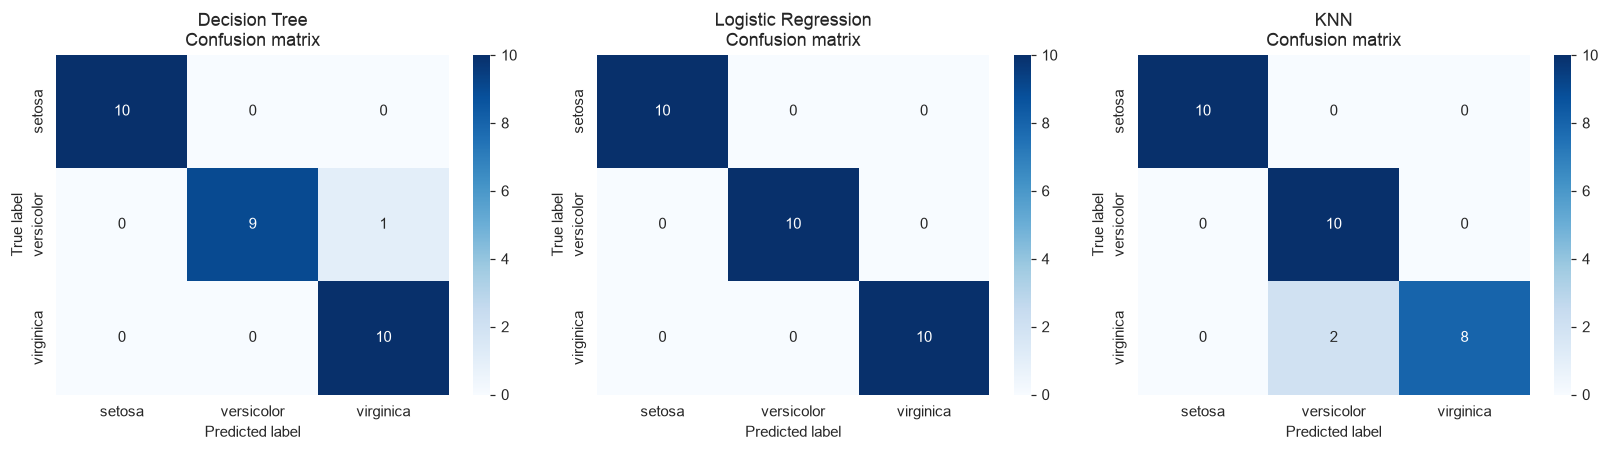

In [166]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, pred[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f"{name}\nConfusion matrix"); ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 1.8 ROC-кривые и AUC (One-vs-Rest)
ROC-кривая для бинарной задачи: двигаем порог вероятности от 1 до 0 и рисуем
**TPR** (доля найденных положительных) против **FPR** (доля ложных тревог).
Чем ближе кривая к левому верхнему углу, тем лучше; **AUC** - площадь под ней (1.0 - идеал, 0.5 - монетка).

У нас 3 класса, поэтому **One-vs-Rest**: для каждого класса задача «этот класс vs все остальные»,
берём соответствующий столбец `predict_proba`. **macro-AUC** = среднее трёх AUC.

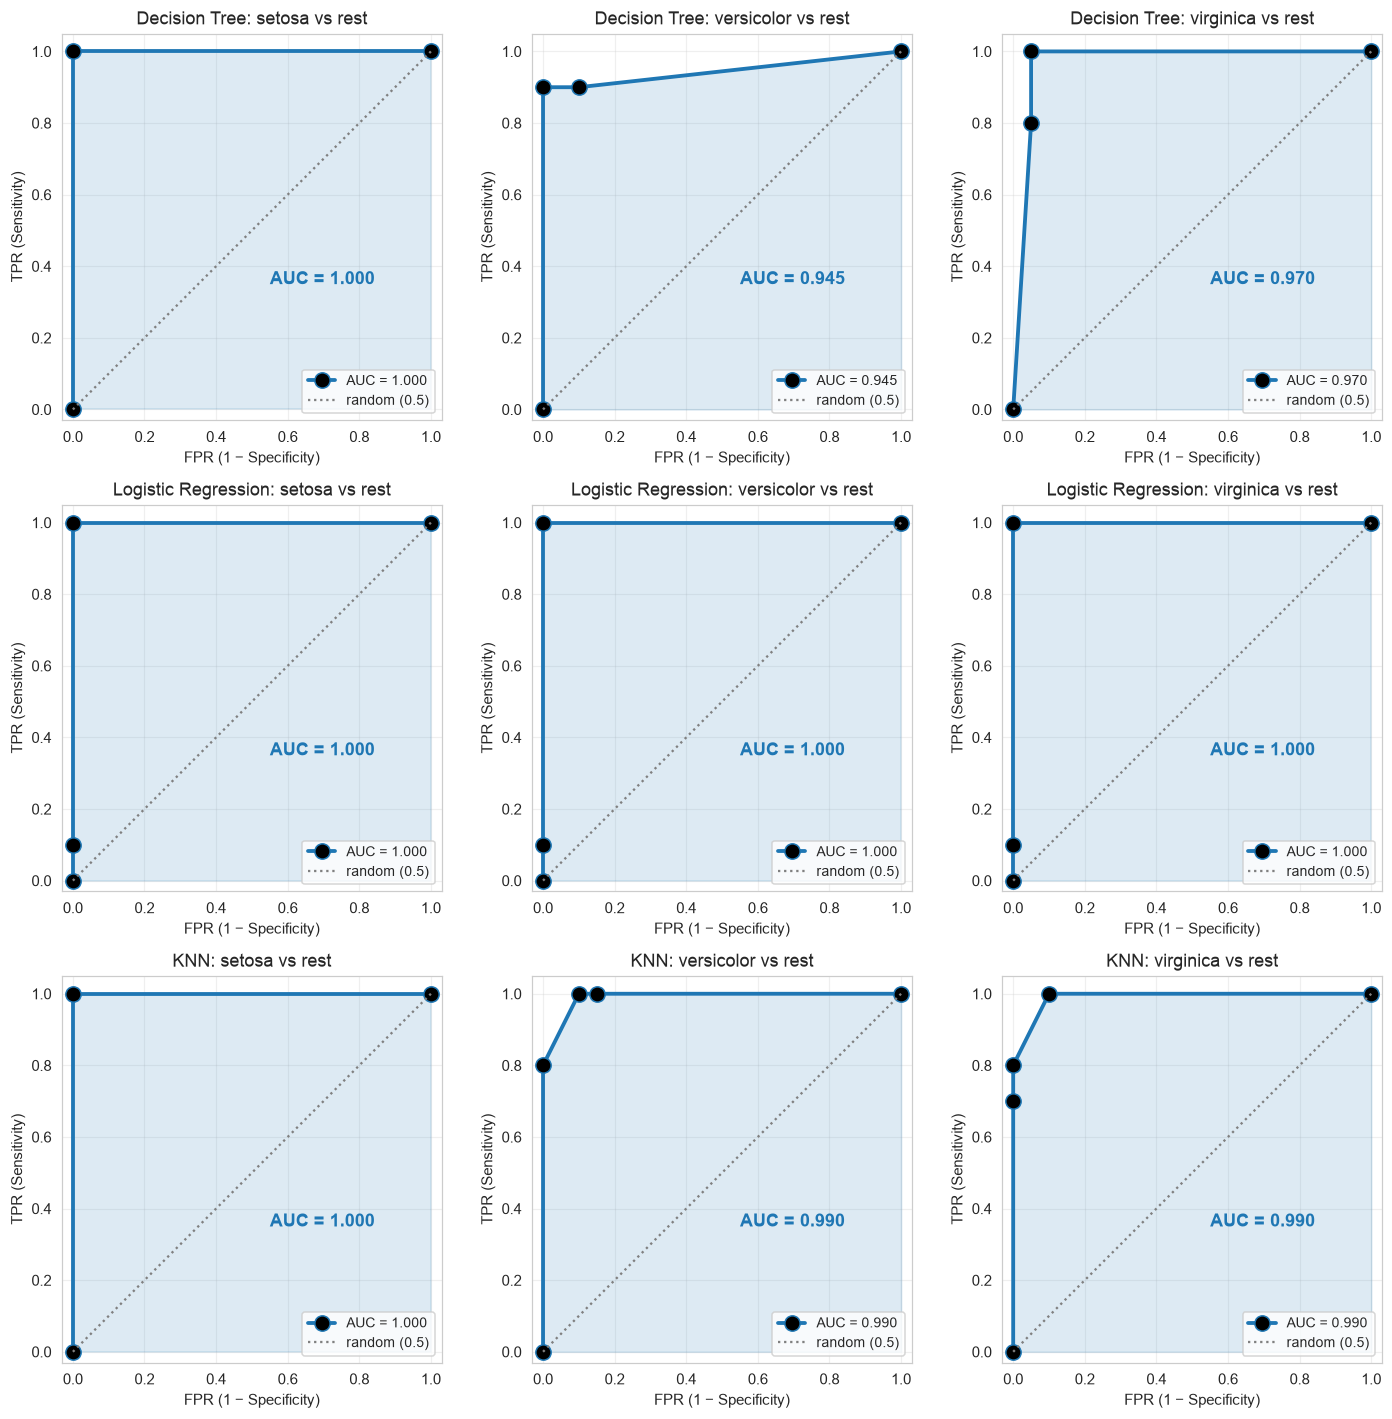

{'Decision Tree': np.float64(0.972), 'Logistic Regression': np.float64(1.0), 'KNN': np.float64(0.993)}


In [167]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
auc_macro = {}
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for row, name in enumerate(models):
    aucs = []
    for c in range(3):
        ax = axes[row, c]
        fpr, tpr, _ = roc_curve(y_test_bin[:, c], proba[name][:, c])
        a = roc_auc_score(y_test_bin[:, c], proba[name][:, c]); aucs.append(a)
        ax.fill_between(fpr, tpr, color="tab:blue", alpha=0.15)   # заливка = AUC
        ax.plot(fpr, tpr, marker="o", lw=2.5, ms=10, color="tab:blue", mfc="black",
                label=f"AUC = {a:.3f}")
        ax.plot([0, 1], [0, 1], color="gray", ls=":", lw=1.5, label="random (0.5)")
        ax.text(0.55, 0.35, f"AUC = {a:.3f}", fontsize=12, color="tab:blue", weight="bold")
        ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.05); ax.set_aspect("equal")
        ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=9)
        ax.set_title(f"{name}: {class_names[c]} vs rest")
        ax.set_xlabel("FPR (1 − Specificity)"); ax.set_ylabel("TPR (Sensitivity)")
    auc_macro[name] = np.mean(aucs)
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in auc_macro.items()})   # macro-AUC по моделям

## 1.9 Сводная таблица результатов

In [168]:
rows = []
for name in models:
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred[name]),
        "Precision (macro)": precision_score(y_test, pred[name], average="macro"),
        "Recall (macro)": recall_score(y_test, pred[name], average="macro"),
        "F1 (macro)": f1_score(y_test, pred[name], average="macro"),
        "AUC (macro, OvR)": auc_macro[name],
        "Train time, ms": train_time[name] * 1000,
        "Predict time, ms": pred_time[name] * 1000,
    })
t1_results = pd.DataFrame(rows).set_index("Model")
t1_results.to_csv("results/task1_metrics.csv")
t1_results.round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),"AUC (macro, OvR)","Train time, ms","Predict time, ms"
Model,,,,,,,
Decision Tree,0.96700,0.97000,0.96700,0.96700,0.97200,1.77900,0.81000
Logistic Regression,1.00000,1.00000,1.00000,1.00000,1.00000,5.08400,1.18000
KNN,0.93300,0.94400,0.93300,0.93300,0.99300,1.95600,3.40400


In [169]:
# Дополнительно: тест всего 30 объектов, одна ошибка = -3.3% accuracy.
# Поэтому смотрим ещё и 5-fold CV на всём датасете - оценка устойчивее.
cv_rows = {name: cross_val_score(m, X, y, cv=cv5, scoring="accuracy") for name, m in models.items()}
pd.DataFrame({n: {"CV accuracy mean": s.mean(), "CV accuracy std": s.std()} for n, s in cv_rows.items()}).T.round(3)

,CV accuracy mean,CV accuracy std
Decision Tree,0.96000,0.02500
Logistic Regression,0.97300,0.03900
KNN,0.94700,0.05400


### Вывод по Task 1
*(Precision, Recall, F1 и AUC - macro-усреднение по 3 классам, AUC - схема One-vs-Rest.)*

1. **Лучший баланс метрик у Logistic Regression**: на тесте все метрики = 1.000 (Accuracy, macro-Precision/Recall/F1 и macro-AUC), и в 5-fold CV у неё тоже лучший результат (0.973).
2. **Decision Tree** (max_depth=3): accuracy и F1 = 0.967, одна ошибка - versicolor принят за virginica. AUC самый низкий (0.972): дерево выдаёт «грубые» вероятности (доли классов в листе), поэтому ROC-кривая ступенчатая.
3. **KNN** (k=3): accuracy и F1 = 0.933 (2 virginica приняты за versicolor), но AUC высокий (0.993). Значит, по вероятностям модель ранжирует объекты почти идеально, а ошибается только на границе при пороге.
4. Setosa все три модели отделяют безошибочно. Все ошибки - между похожими versicolor и virginica.
5. Почему так: по признакам лепестка классы Iris почти линейно разделимы, поэтому линейной границы LR достаточно, а слабая регуляризация (C=10) позволяет ей точно подстроиться. KNN чувствителен к масштабу (мы его стандартизировали) и к локальному шуму на границе классов при малом k. Дерево без ограничения глубины переобучается, поэтому GridSearch выбрал depth=3.
6. Оговорка: в тесте всего 30 объектов, и одна ошибка = 3.3 п.п. accuracy, так что разница между моделями сравнима с шумом. Кросс-валидация подтверждает порядок LR > DT > KNN.

---
# Task 2. Feature Engineering и Dimensionality Reduction

Используем то же разбиение Iris (80/20, stratify). Масштабирование делаем внутри пайплайна для KNN

## 2.2 Важность признаков (Feature Importances) у Decision Tree
Дерево на каждом разбиении выбирает признак, который сильнее всего уменьшает «перемешанность» классов (Gini impurity).
**feature_importances_** - суммарное уменьшение Gini, которое дал каждый признак, нормированное до суммы 1.

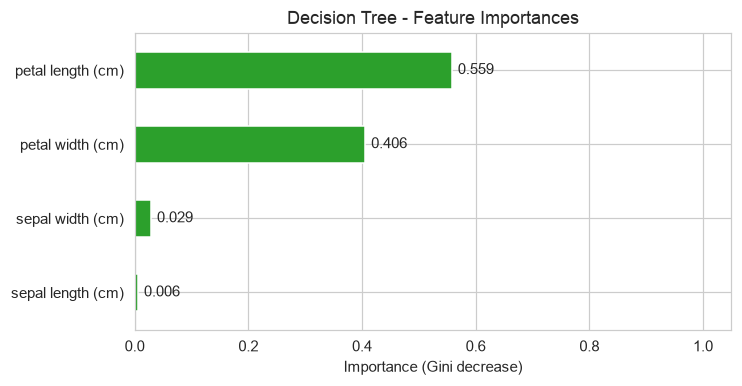

petal length (cm)   0.55900
petal width (cm)    0.40600
sepal width (cm)    0.02900
sepal length (cm)   0.00600
dtype: float64

In [170]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)   # без ограничений, как "чистая" модель
dt.fit(X_train, y_train)
imp = pd.Series(dt.feature_importances_, index=feature_names).sort_values()

ax = imp.plot.barh(figsize=(7, 3.5), color="tab:green")
for i, v in enumerate(imp.values): ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlabel("Importance (Gini decrease)"); ax.set_title("Decision Tree - Feature Importances"); ax.set_xlim(0, 1.05)
plt.show()
imp.sort_values(ascending=False).round(3)

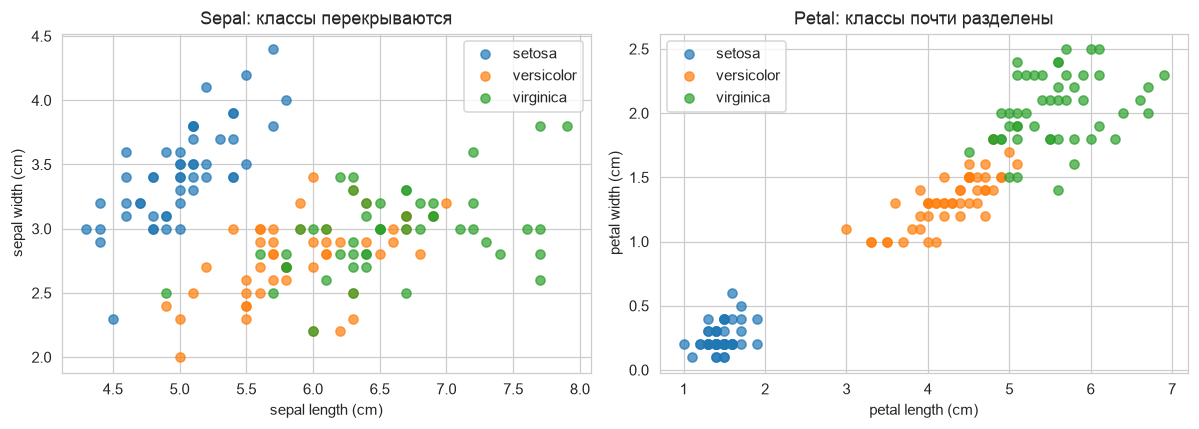

In [171]:
# Почему petal-признаки важнее: посмотрим, как классы разделяются по каждой паре признаков
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (i, j) in zip(axes, [(0, 1), (2, 3)]):
    for c in range(3):
        ax.scatter(X[y == c, i], X[y == c, j], label=class_names[c], alpha=0.7)
    ax.set_xlabel(feature_names[i]); ax.set_ylabel(feature_names[j]); ax.legend()
axes[0].set_title("Sepal: классы перекрываются"); axes[1].set_title("Petal: классы почти разделены")
plt.tight_layout(); plt.show()

## 2.3 Confusion Matrix лучшей модели из Task 1
Лучшую модель выбираем по сводной таблице Task 1 (accuracy, при равенстве - F1-macro, затем AUC)

Лучшая модель: Logistic Regression


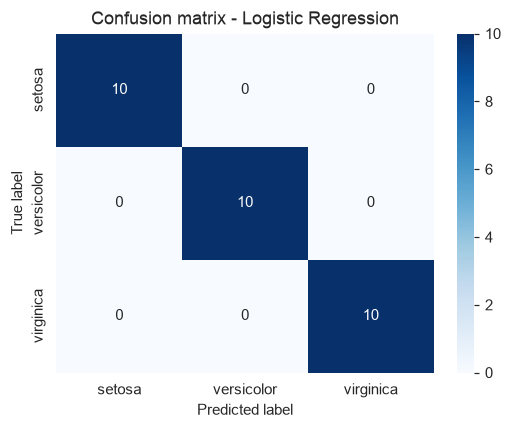

Decision Tree        ошибки (true → predicted, кол-во): [(np.str_('versicolor'), np.str_('virginica'), np.int64(1))]
Logistic Regression  ошибки (true → predicted, кол-во): нет
KNN                  ошибки (true → predicted, кол-во): [(np.str_('virginica'), np.str_('versicolor'), np.int64(2))]


In [172]:
best_name = t1_results.sort_values(["Accuracy", "F1 (macro)", "AUC (macro, OvR)"], ascending=False).index[0]
print("Лучшая модель:", best_name)
cm = confusion_matrix(y_test, pred[best_name])
# noinspection PyTypeChecker
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion matrix - {best_name}"); plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.tight_layout(); plt.show()

# Матрицы всех трёх моделей вместе: где ошибки?
for name in models:
    cm_ = confusion_matrix(y_test, pred[name])
    errs = [(class_names[i], class_names[j], cm_[i, j]) for i in range(3) for j in range(3) if i != j and cm_[i, j] > 0]
    print(f"{name:20s} ошибки (true → predicted, кол-во): {errs if errs else 'нет'}")

## 2.4 a) KNN: влияние числа соседей k (1…20)
Тест - всего 30 объектов, кривая будет «ступенчатой». Поэтому рядом рисуем и **5-fold CV accuracy на train** - она гладче и надёжнее для выбора k

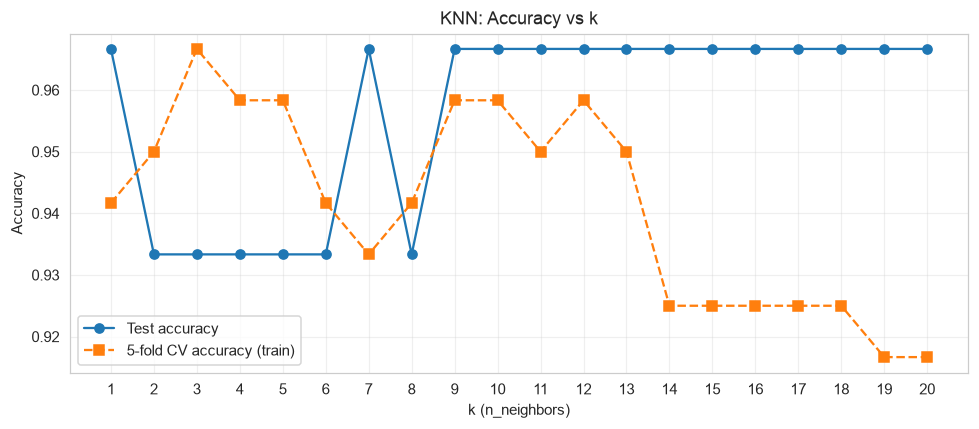

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
k,1.00000,2.00000,3.00000,4.00000,5.00000,6.00000,7.00000,8.00000,9.00000,10.00000,11.00000,12.00000,13.00000,14.00000,15.00000,16.00000,17.00000,18.00000,19.00000,20.00000
test_acc,0.96700,0.93300,0.93300,0.93300,0.93300,0.93300,0.96700,0.93300,0.96700,0.96700,0.96700,0.96700,0.96700,0.96700,0.96700,0.96700,0.96700,0.96700,0.96700,0.96700
cv_acc,0.94200,0.95000,0.96700,0.95800,0.95800,0.94200,0.93300,0.94200,0.95800,0.95800,0.95000,0.95800,0.95000,0.92500,0.92500,0.92500,0.92500,0.92500,0.91700,0.91700


In [173]:
ks = range(1, 21)
knn_test, knn_cv = [], []
for k in ks:
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))])
    knn_cv.append(cross_val_score(pipe, X_train, y_train, cv=cv5).mean())
    knn_test.append(pipe.fit(X_train, y_train).score(X_test, y_test))

# noinspection PyTypeChecker
plt.figure(figsize=(9, 4))
plt.plot(ks, knn_test, "o-", label="Test accuracy")
plt.plot(ks, knn_cv, "s--", label="5-fold CV accuracy (train)")
plt.xticks(list(ks)); plt.xlabel("k (n_neighbors)"); plt.ylabel("Accuracy"); plt.title("KNN: Accuracy vs k")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()
knn_df = pd.DataFrame({"k": list(ks), "test_acc": knn_test, "cv_acc": knn_cv}).round(3)
knn_df.T

## 2.4 b) Decision Tree: влияние глубины max_depth (1…10)
Сравниваем accuracy на train и test на одном графике - классическая картина недообучения/переобучения

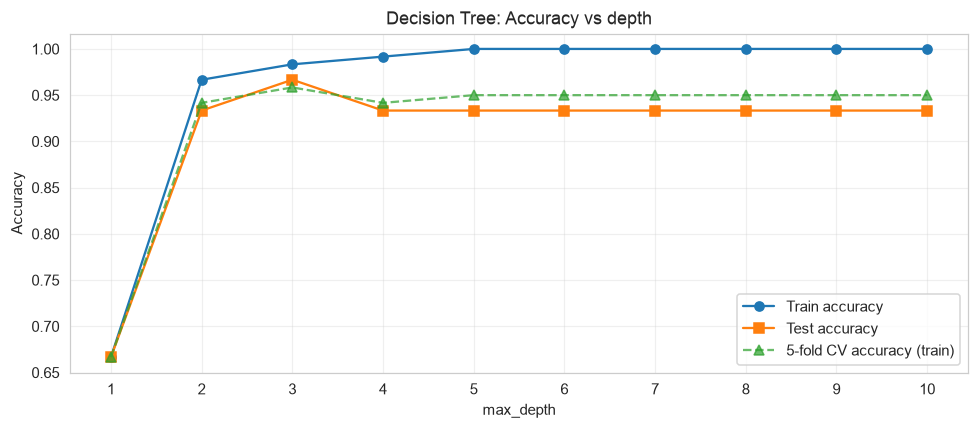

Фактическая глубина неограниченного дерева: 5 | листьев: 8


,0,1,2,3,4,5,6,7,8,9
depth,1.00000,2.00000,3.00000,4.00000,5.00000,6.00000,7.00000,8.00000,9.00000,10.00000
train,0.66700,0.96700,0.98300,0.99200,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000
test,0.66700,0.93300,0.96700,0.93300,0.93300,0.93300,0.93300,0.93300,0.93300,0.93300
cv,0.66700,0.94200,0.95800,0.94200,0.95000,0.95000,0.95000,0.95000,0.95000,0.95000


In [174]:
depths = range(1, 11)
dt_train, dt_test, dt_cv = [], [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    dt_train.append(m.score(X_train, y_train)); dt_test.append(m.score(X_test, y_test))
    dt_cv.append(cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE), X_train, y_train, cv=cv5).mean())

# noinspection PyTypeChecker
plt.figure(figsize=(9, 4))
plt.plot(depths, dt_train, "o-", label="Train accuracy")
plt.plot(depths, dt_test, "s-", label="Test accuracy")
plt.plot(depths, dt_cv, "^--", alpha=0.7, label="5-fold CV accuracy (train)")
plt.xticks(list(depths)); plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Decision Tree: Accuracy vs depth")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()
print("Фактическая глубина неограниченного дерева:", dt.get_depth(), "| листьев:", dt.get_n_leaves())
pd.DataFrame({"depth": list(depths), "train": dt_train, "test": dt_test, "cv": dt_cv}).round(3).T

### Выводы по Task 2

**Важность признаков.** У дерева решение почти полностью определяется лепестком: *petal length* = 0.559 и *petal width* = 0.406, вместе ≈ 96.5%. На sepal приходится всего ≈ 3.5%. Причина видна на scatter-графиках: по petal-признакам setosa отделяется одним порогом, а versicolor и virginica перекрываются мало. По sepal-признакам все три класса сильно перемешаны

**Confusion matrix.** Лучшая модель из Task 1 (Logistic Regression) на тесте не ошиблась ни разу. У других моделей все ошибки - между **versicolor и virginica** (у DT: 1 versicolor → virginica, у KNN: 2 virginica → versicolor). Setosa всегда распознаётся безошибочно. Перекрёстные ошибки возникают только между похожими классами

**KNN, k = 1…20.** Тестовая кривая ступенчатая (0.933 ↔ 0.967): на 30 объектах одна ошибка меняет accuracy на 3.3 п.п. Поэтому выбор k делаем по CV-кривой
- k = 1: CV = 0.942. Модель запоминает шум отдельных точек (переобучение)
- k ≈ 3–12: CV 0.95–0.967, это оптимальный и самый стабильный диапазон (максимум при k = 3)
- k ≥ 14: CV падает до 0.917–0.925. Голосует слишком много соседей, в том числе из чужого класса, и граница «размывается» (потеря чувствительности, недообучение)

**Decision Tree, max_depth = 1…10.**
- depth = 1: train = test = 0.667. Одним вопросом дерево отделяет только setosa (недообучение)
- depth = 3: лучший баланс (train 0.983, **test 0.967**, CV 0.958)
- depth ≥ 5: train = 1.000, а test падает до 0.933. Дерево «запомнило» обучающую выборку (переобучение). Дальше кривые не меняются, потому что неограниченное дерево вырастает только до глубины 5

**Общий вывод.** Самые важные признаки - размеры лепестка. Лучшие настройки: LR (C=10), KNN с k ≈ 3–12 (масштабирование обязательно), дерево с max_depth = 3. Если не считать вырожденный случай depth = 1, **KNN устойчивее к изменению своего гиперпараметра**: при любом k из 1–20 accuracy держится в пределах 0.917–0.967. Дерево резко меняется при малой глубине и уходит в переобучение при большой, так что его глубину обязательно нужно ограничивать

---
# Task 3. Простой перцептрон (PyTorch): ReLU vs Sigmoid vs Tanh

**Датасет: Breast Cancer Wisconsin** (569 пациентов, 30 признаков опухоли, 2 класса: malignant / benign).
Выбран вместо Iris, потому что в Iris тест при 60/20/20 - всего 30 объектов, и разница между активациями утонет в шуме

**Архитектура:** `Linear(30 → 16) → активация → Linear(16 → 2)`
Выход - 2 «сырых» числа (logits), `CrossEntropyLoss` сам применяет softmax внутри

**Зачем активация?** Без неё два линейных слоя схлопываются в один линейный - сеть не сможет выучить нелинейные зависимости
- **Sigmoid**: σ(x)=1/(1+e⁻ˣ), выход (0,1). На краях почти плоская → градиент ≈0 («насыщение»), max производная всего 0.25
- **Tanh**: выход (−1,1), центрирован в 0, max производная 1 - учится быстрее sigmoid, но тоже насыщается
- **ReLU**: max(0,x). Кусочно-линейная, градиент = 1 для x>0 → не насыщается, считается дёшево

## 3.1 Данные: 60/20/20, StandardScaler только на train

Загрузка и подготовка данных
- Выбрать датасет (Iris / Breast Cancer).
- Разделить на train/valid/test (60/20/20).
- Обучить StandardScaler на train, применить к valid и test.
- Сохранить размеры выборок, классовый баланс.



In [175]:
bc = load_breast_cancer()
Xb, yb = bc.data, bc.target
Xb_tmp, Xb_test, yb_tmp, yb_test = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=RANDOM_STATE)
Xb_train, Xb_val, yb_train, yb_val = train_test_split(Xb_tmp, yb_tmp, test_size=0.25, stratify=yb_tmp, random_state=RANDOM_STATE)  # 0.25*0.8 = 0.2

scaler_b = StandardScaler().fit(Xb_train)                 # fit на train - иначе утечка информации
Xb_train_s, Xb_val_s, Xb_test_s = (scaler_b.transform(a) for a in (Xb_train, Xb_val, Xb_test))

split_info = pd.DataFrame({
    "size": [len(yb_train), len(yb_val), len(yb_test)],
    "malignant / злокачественная опухоль (0)": [np.sum(a == 0) for a in (yb_train, yb_val, yb_test)],
    "benign / доброкачественная (не рак, неопасная) (1)": [np.sum(a == 1) for a in (yb_train, yb_val, yb_test)],
}, index=["train", "valid", "test"])
split_info

,size,malignant / злокачественная опухоль (0),"benign / доброкачественная (не рак, неопасная) (1)"
train,341,127,214
valid,114,43,71
test,114,42,72


## 3.2–3.3 Модель (активация - параметр) и единый цикл обучения с ранней остановкой

Конфигурация эксперимента
- Зафиксировать сиды
- Определить единый конфиг гиперпараметров (lr, batch size, epochs, hidden_dim, weight_decay)
- Единая инициализация весов/логика сохранения лучших весов

Реализация модели (один скрытый слой)
- PyTorch: nn.Linear(input_dim, hidden_dim) → activation → nn.Linear(hidden_dim, out_dim)
- TensorFlow: Dense(hidden_dim, activation=None) → ручное добавление активации → Dense(out_dim) (без activation, если используете «from_logits»)
- Вынести активацию параметром ("relu" | "sigmoid" | "tanh"), чтобы цикл по активациям не дублировал код

In [176]:
ACTIVATIONS = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh}

class Perceptron(nn.Module):
    def __init__(self, input_dim, hidden_dim, out_dim, activation):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), # 30 → 16
            ACTIVATIONS[activation](),        # ReLU / Sigmoid / Tanh
            nn.Linear(hidden_dim, out_dim),   # 16 → 2
        )
    def forward(self, x):
        return self.net(x)

to_t = lambda a, dtype=torch.float32: torch.tensor(a, dtype=dtype)
Xtr_t, Xva_t, Xte_t = to_t(Xb_train_s), to_t(Xb_val_s), to_t(Xb_test_s)
ytr_t, yva_t, yte_t = to_t(yb_train, torch.long), to_t(yb_val, torch.long), to_t(yb_test, torch.long)

def evaluate(model, X_t, y_t, loss_fn):
    model.eval()
    with torch.no_grad():
        logits = model(X_t)
        return loss_fn(logits, y_t).item(), (logits.argmax(1) == y_t).float().mean().item()

def train_perceptron(activation, cfg, seed):
    set_seed(seed)
    model = Perceptron(Xtr_t.shape[1], cfg["hidden_dim"], 2, activation)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(seed)           # одинаковый порядок мини-батчей
    hist = {k: [] for k in ["train_loss", "valid_loss", "train_acc", "valid_acc"]}
    best_val, best_state, best_epoch, wait = np.inf, None, 0, 0

    for epoch in range(cfg["max_epochs"]):
        model.train()
        perm = torch.randperm(len(Xtr_t), generator=g)
        for i in range(0, len(perm), cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            loss = loss_fn(model(Xtr_t[idx]), ytr_t[idx])   # forward + loss
            opt.zero_grad(); loss.backward(); opt.step()    # backprop + шаг оптимизатора
        tl, ta = evaluate(model, Xtr_t, ytr_t, loss_fn); vl, va = evaluate(model, Xva_t, yva_t, loss_fn)
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)

        if vl < best_val - 1e-5:                           # ранняя остановка по valid loss
            best_val, best_epoch, wait = vl, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]: break
    model.load_state_dict(best_state)                      # восстанавливаем лучшие веса
    return model, hist, best_epoch

## 3.4–3.5 Обучение для каждой активации и оценка на test

In [177]:
t3_models, t3_hist, t3_rows = {}, {}, []
for act in T3_CFG["activations"]:
    t0 = time.perf_counter()
    model, hist, best_ep = train_perceptron(act, T3_CFG, seed=RANDOM_STATE)
    dur = time.perf_counter() - t0
    model.eval()
    with torch.no_grad(): yp = model(Xte_t).argmax(1).numpy()
    t3_models[act], t3_hist[act] = model, hist
    t3_rows.append({"Activation": act, "Test Accuracy": accuracy_score(yb_test, yp),
                    "Precision": precision_score(yb_test, yp, average="macro"),
                    "Recall": recall_score(yb_test, yp, average="macro"),
                    "F1": f1_score(yb_test, yp, average="macro"),
                    "Best epoch": best_ep + 1, "Epochs run": len(hist["train_loss"]),
                    "Best valid loss": min(hist["valid_loss"]), "Time, s": dur})
t3_results = pd.DataFrame(t3_rows).set_index("Activation")
t3_results.to_csv("results/task3_metrics.csv")
with open("results/task3_metrics.md", "w") as f: f.write(t3_results.round(4).to_markdown())
t3_results.round(4)

,Test Accuracy,Precision,Recall,F1,Best epoch,Epochs run,Best valid loss,"Time, s"
Activation,,,,,,,,
relu,0.97370,0.96970,0.97420,0.97190,175,195,0.05860,1.04550
sigmoid,0.94740,0.93830,0.95340,0.94450,297,300,0.04390,1.38340
tanh,0.97370,0.96970,0.97420,0.97190,213,233,0.04040,1.03190


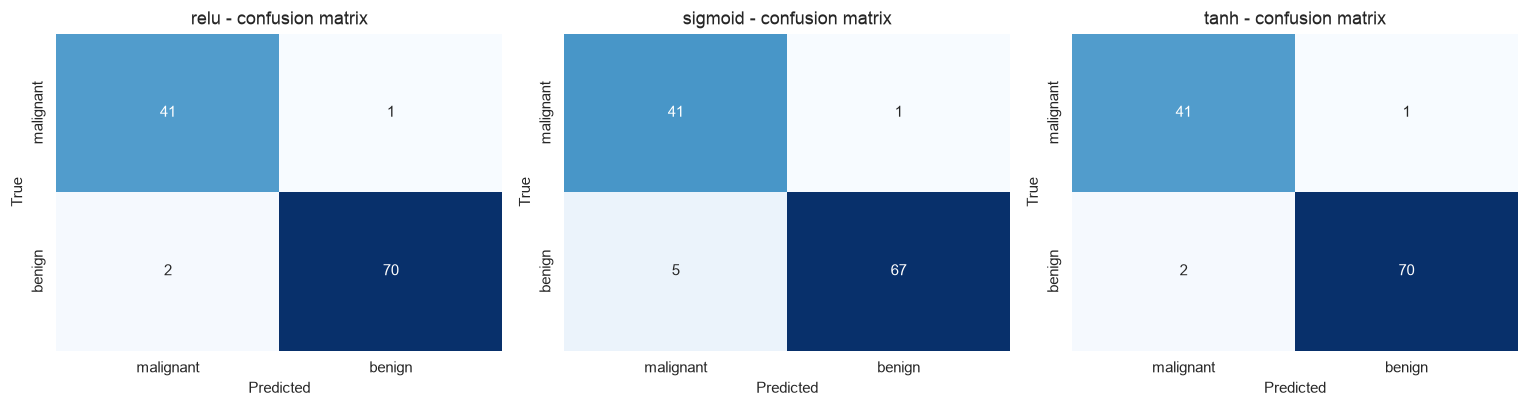

In [178]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, act in zip(axes, T3_CFG["activations"]):
    with torch.no_grad(): yp = t3_models[act](Xte_t).argmax(1).numpy()
    sns.heatmap(confusion_matrix(yb_test, yp), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=bc.target_names, yticklabels=bc.target_names)
    ax.set_title(f"{act} - confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

## 3.6 Визуализация: learning curves и bar chart

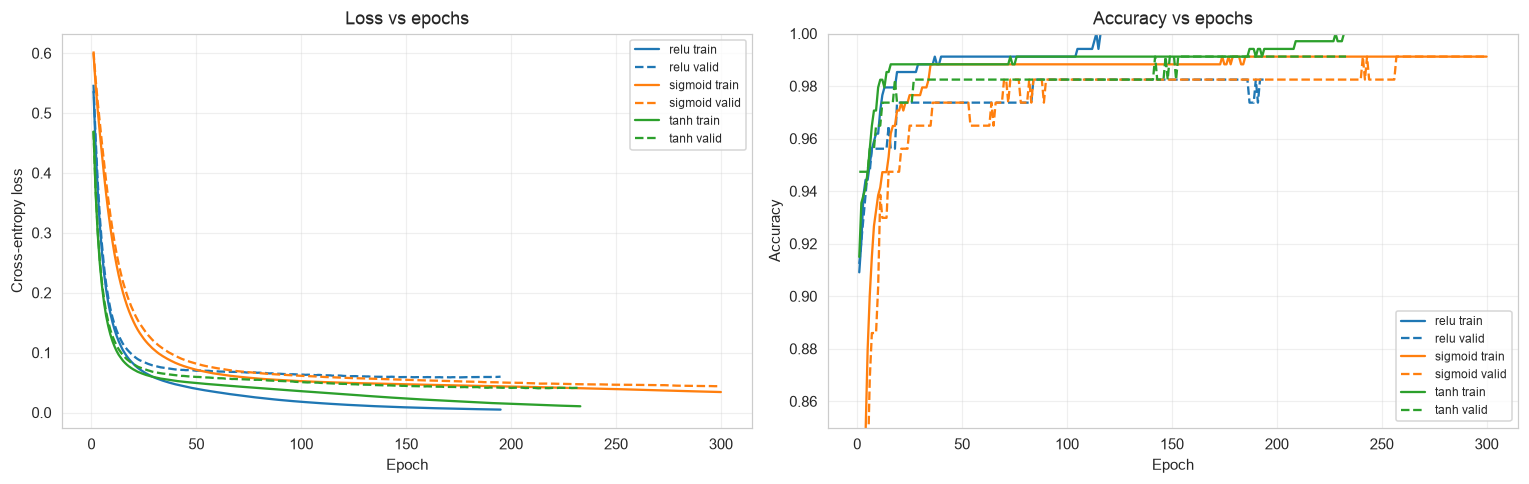

In [179]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = {"relu": "tab:blue", "sigmoid": "tab:orange", "tanh": "tab:green"}
for act, h in t3_hist.items():
    ep = np.arange(1, len(h["train_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], color=colors[act], label=f"{act} train")
    axes[0].plot(ep, h["valid_loss"], color=colors[act], ls="--", label=f"{act} valid")
    axes[1].plot(ep, h["train_acc"], color=colors[act], label=f"{act} train")
    axes[1].plot(ep, h["valid_acc"], color=colors[act], ls="--", label=f"{act} valid")
axes[0].set_title("Loss vs epochs"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_title("Accuracy vs epochs"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].set_ylim(0.85, 1.0)
for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

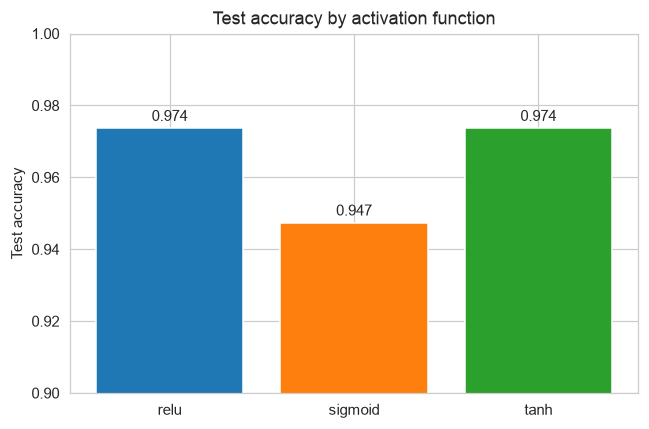

In [180]:
# noinspection PyTypeChecker
plt.figure(figsize=(6, 4))
bars = plt.bar(t3_results.index, t3_results["Test Accuracy"], color=[colors[a] for a in t3_results.index])
for b, v in zip(bars, t3_results["Test Accuracy"]): plt.text(b.get_x() + b.get_width()/2, v + 0.002, f"{v:.3f}", ha="center")
plt.ylim(0.9, 1.0); plt.ylabel("Test accuracy"); plt.title("Test accuracy by activation function")
plt.tight_layout(); plt.show()

## 3.7 Устойчивость: повтор на 5 сидах
Один запуск может быть случайно удачным. Повторяем обучение с 5 разными сидами (меняются начальные веса и порядок батчей; данные и гиперпараметры те же).

In [181]:
stab = []
for act in T3_CFG["activations"]:
    for s in T3_CFG["stability_seeds"]:
        m, h, be = train_perceptron(act, T3_CFG, seed=s)
        with torch.no_grad(): acc = (m(Xte_t).argmax(1) == yte_t).float().mean().item()
        stab.append({"activation": act, "seed": s, "test_acc": acc, "best_epoch": be + 1,
                     "epochs_to_valid_loss_0.15": next((i + 1 for i, v in enumerate(h["valid_loss"]) if v < 0.15), None)})
stab_df = pd.DataFrame(stab)
stab_summary = stab_df.groupby("activation").agg(acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
                                                 best_epoch_mean=("best_epoch", "mean"),
                                                 epochs_to_loss_015=("epochs_to_valid_loss_0.15", "mean"))
stab_summary.round(4)

,acc_mean,acc_std,best_epoch_mean,epochs_to_loss_015
activation,,,,
relu,0.95960,0.01180,177.00000,12.20000
sigmoid,0.94740,0.00000,276.80000,28.00000
tanh,0.97190,0.00390,245.00000,10.20000


**Справедливое сравнение:** у всех трёх активаций одинаковые данные, разбиение, scaler, архитектура (30→16→2),
оптимизатор Adam, lr, batch size, weight decay, patience, сид инициализации и порядок батчей. Отличается **только функция активации**.

### Анализ и выводы по Task 3

**Какая активация сошлась быстрее?** Tanh: valid loss опускается ниже 0.15 в среднем за ~10 эпох, у ReLU за ~12, у Sigmoid за ~28. Sigmoid - самая медленная: она дошла до лимита в 300 эпох (лучшая эпоха 297), не сработав на ранней остановке, то есть всё ещё медленно улучшалась.

**Какая дала лучший результат на test?** В основном запуске (seed=42) у ReLU и Tanh одинаковая accuracy = 0.974 (3 ошибки из 114) и F1 = 0.972. У Sigmoid accuracy = 0.947 (6 ошибок), F1 = 0.945.

**Устойчивость (5 сидов):** Tanh 0.972 ± 0.004 - лучшая и стабильная. ReLU 0.960 ± 0.012 - заметнее зависит от начальных весов. Sigmoid 0.947 ± 0.000 - стабильная, но стабильно хуже.

**Наблюдение:** ReLU сильнее всех «выжимает» train (train loss → ~0.007), но valid loss у неё перестаёт снижаться раньше, чем у остальных: признак лёгкого переобучения. При этом у Sigmoid valid loss ниже, а test accuracy хуже. На маленьких выборках (114 объектов) loss и accuracy не обязаны совпадать.

**Гипотезы, почему так:**
- *Sigmoid*: производная не больше 0.25, на краях почти 0 (насыщение), а выходы не центрированы относительно 0 (всегда > 0). Градиенты маленькие, обучение медленное, и с одинаковым lr сеть не успевает «дожать» решение.
- *Tanh*: выход центрирован в 0, производная в нуле = 1. На стандартизированных данных большинство нейронов работает в линейной, ненасыщенной зоне, поэтому обучение быстрое и гладкое.
- *ReLU*: не насыщается при x>0 и быстро снижает loss. Но она кусочно-линейная, и часть из 16 нейронов может «умереть» (выход 0 → градиент 0). Отсюда больший разброс между сидами.

**Рекомендация:** для небольших табличных задач с маленьким скрытым слоем стоит выбрать **Tanh** или **ReLU** (Tanh здесь чуть точнее и стабильнее). ReLU - стандартный выбор для глубоких сетей. Sigmoid в скрытых слоях лучше не использовать: она годится для выходного слоя бинарной классификации, где нужна вероятность.

---
# Task 4. MLP на MNIST: влияние числа эпох и batch size

**MNIST** - 70 000 рукописных цифр 28×28 пикселей (60k train, 10k test), 10 классов.
**MLP** - каждое изображение «разворачиваем» в вектор из 784 чисел и подаём в полносвязную сеть:
`784 → 256 → 128 → 64 → 10`, ReLU между слоями.

На выходе 10 logits; **Softmax** превращает их в вероятности. В PyTorch `CrossEntropyLoss` = LogSoftmax + NLLLoss,
поэтому softmax явно применяем только при выводе вероятностей.

**Термины:**
- **Эпоха** - один полный проход по всему train.
- **Batch size** - сколько картинок обрабатываем перед одним шагом градиентного спуска. Маленький батч → больше шагов за эпоху, градиент «шумнее»; большой → меньше шагов, градиент точнее, эпоха быстрее.

## 4.1 Данные

train (54000, 784) | valid (6000, 784) | test (10000, 784)
pixel range: 0.0 … 1.0
баланс классов в train: [5328, 6099, 5357, 5506, 5277, 4868, 5333, 5638, 5219, 5375]


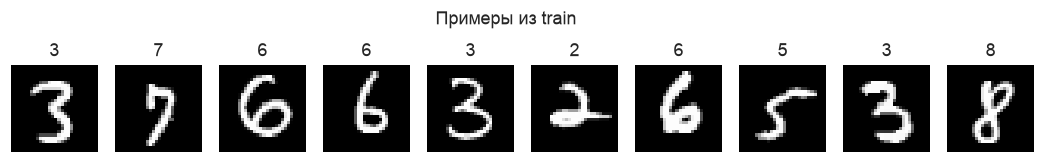

In [182]:
from torchvision import datasets
mnist_train = datasets.MNIST("data", train=True, download=True)
mnist_test = datasets.MNIST("data", train=False, download=True)

# Нормализация пикселей 0..255 → 0..1, разворачиваем 28×28 → 784
Xall = mnist_train.data.float().div(255).view(-1, 784); yall = mnist_train.targets
Xm_test = mnist_test.data.float().div(255).view(-1, 784); ym_test = mnist_test.targets

# Валидация: 6000 случайных картинок из train (10%)
g = torch.Generator().manual_seed(RANDOM_STATE)
perm = torch.randperm(len(Xall), generator=g)
val_idx, tr_idx = perm[:T4_CFG["val_size"]], perm[T4_CFG["val_size"]:]
Xm_tr, ym_tr, Xm_val, ym_val = Xall[tr_idx], yall[tr_idx], Xall[val_idx], yall[val_idx]
print(f"train {tuple(Xm_tr.shape)} | valid {tuple(Xm_val.shape)} | test {tuple(Xm_test.shape)}")
print("pixel range:", Xm_tr.min().item(), "…", Xm_tr.max().item())
print("баланс классов в train:", torch.bincount(ym_tr).tolist())

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(Xm_tr[i].view(28, 28), cmap="gray"); ax.set_title(int(ym_tr[i])); ax.axis("off")
plt.suptitle("Примеры из train", y=1.05); plt.show()

## 4.2 Архитектура MLP и функция обучения

In [183]:
class MLP(nn.Module):
    def __init__(self, hidden=(256, 128, 64), n_in=784, n_out=10):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]; prev = h
        layers.append(nn.Linear(prev, n_out))          # logits; softmax внутри CrossEntropyLoss
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

@torch.no_grad()
def eval_mlp(model, X_, y_, loss_fn, bs=2048):
    model.eval(); loss_sum, correct = 0.0, 0
    for i in range(0, len(X_), bs):
        out = model(X_[i:i + bs]); loss_sum += loss_fn(out, y_[i:i + bs]).item() * len(out)
        correct += (out.argmax(1) == y_[i:i + bs]).sum().item()
    return loss_sum / len(X_), correct / len(X_)

def train_mlp(epochs, batch_size, seed=RANDOM_STATE):
    set_seed(seed)
    model = MLP(T4_CFG["hidden"])
    opt = torch.optim.Adam(model.parameters(), lr=T4_CFG["lr"]); loss_fn = nn.CrossEntropyLoss()
    gen = torch.Generator().manual_seed(seed)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    t0 = time.perf_counter()
    for ep in range(epochs):
        model.train(); run_loss, run_correct = 0.0, 0
        perm = torch.randperm(len(Xm_tr), generator=gen)
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            out = model(Xm_tr[idx]); loss = loss_fn(out, ym_tr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            run_loss += loss.item() * len(idx); run_correct += (out.argmax(1) == ym_tr[idx]).sum().item()
        vl, va = eval_mlp(model, Xm_val, ym_val, loss_fn)
        hist["train_loss"].append(run_loss / len(Xm_tr)); hist["train_acc"].append(run_correct / len(Xm_tr))
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
    return model, hist, time.perf_counter() - t0

## 4.3–4.4 Эксперименты: 3 × 3 = 9 комбинаций
Всё фиксировано (архитектура, Adam lr=1e-3, сид, разбиение) - меняются только **epochs** и **batch size**.
Каждая комбинация обучается с нуля

In [184]:
t4_runs, t4_rows = {}, []
for bs in T4_CFG["batch_grid"]:
    for ep in T4_CFG["epochs_grid"]:
        model, hist, dur = train_mlp(ep, bs)
        test_loss, test_acc = eval_mlp(model, Xm_test, ym_test, nn.CrossEntropyLoss())
        t4_runs[(ep, bs)] = (model, hist)
        t4_rows.append({"epochs": ep, "batch_size": bs,
                        "train_acc": hist["train_acc"][-1], "train_loss": hist["train_loss"][-1],
                        "val_acc": hist["val_acc"][-1], "val_loss": hist["val_loss"][-1],
                        "best_val_acc": max(hist["val_acc"]), "min_val_loss": min(hist["val_loss"]),
                        "test_acc": test_acc, "test_loss": test_loss, "time_s": dur})
        print(f"epochs={ep:2d} batch={bs:3d} | val_acc={hist['val_acc'][-1]:.4f} test_acc={test_acc:.4f} "
              f"test_loss={test_loss:.4f} | {dur:.0f}s")
t4_results = pd.DataFrame(t4_rows)
t4_results.to_csv("results/task4_results.csv", index=False)

epochs= 5 batch= 32 | val_acc=0.9733 test_acc=0.9750 test_loss=0.0939 | 11s
epochs=10 batch= 32 | val_acc=0.9747 test_acc=0.9797 test_loss=0.0893 | 22s
epochs=20 batch= 32 | val_acc=0.9773 test_acc=0.9771 test_loss=0.1255 | 45s
epochs= 5 batch= 64 | val_acc=0.9717 test_acc=0.9761 test_loss=0.0833 | 6s
epochs=10 batch= 64 | val_acc=0.9785 test_acc=0.9789 test_loss=0.0882 | 12s
epochs=20 batch= 64 | val_acc=0.9773 test_acc=0.9793 test_loss=0.1120 | 22s
epochs= 5 batch=128 | val_acc=0.9723 test_acc=0.9746 test_loss=0.0776 | 3s
epochs=10 batch=128 | val_acc=0.9755 test_acc=0.9774 test_loss=0.0886 | 6s
epochs=20 batch=128 | val_acc=0.9767 test_acc=0.9765 test_loss=0.1192 | 14s


## 4.5 Таблица результатов

In [185]:
t4_results.round(4)

,epochs,batch_size,train_acc,train_loss,val_acc,val_loss,best_val_acc,min_val_loss,test_acc,test_loss,time_s
0,5,32,0.98640,0.04270,0.97330,0.09920,0.97430,0.08830,0.97500,0.09390,11.13600
1,10,32,0.99340,0.02040,0.97470,0.11450,0.97850,0.08340,0.97970,0.08930,22.37070
2,20,32,0.99660,0.01210,0.97730,0.13580,0.98020,0.08340,0.97710,0.12550,45.37990
3,5,64,0.98490,0.04630,0.97170,0.09540,0.97320,0.08790,0.97610,0.08330,5.60890
4,10,64,0.99430,0.01770,0.97850,0.10480,0.98100,0.08340,0.97890,0.08820,11.65940
5,20,64,0.99680,0.01010,0.97730,0.11880,0.98100,0.08340,0.97930,0.11200,22.49260
6,5,128,0.98240,0.05770,0.97230,0.08950,0.97230,0.08950,0.97460,0.07760,3.09510
7,10,128,0.99380,0.01960,0.97550,0.09090,0.97700,0.07920,0.97740,0.08860,6.32250
8,20,128,0.99820,0.00510,0.97670,0.13870,0.97720,0.07920,0.97650,0.11920,14.02790


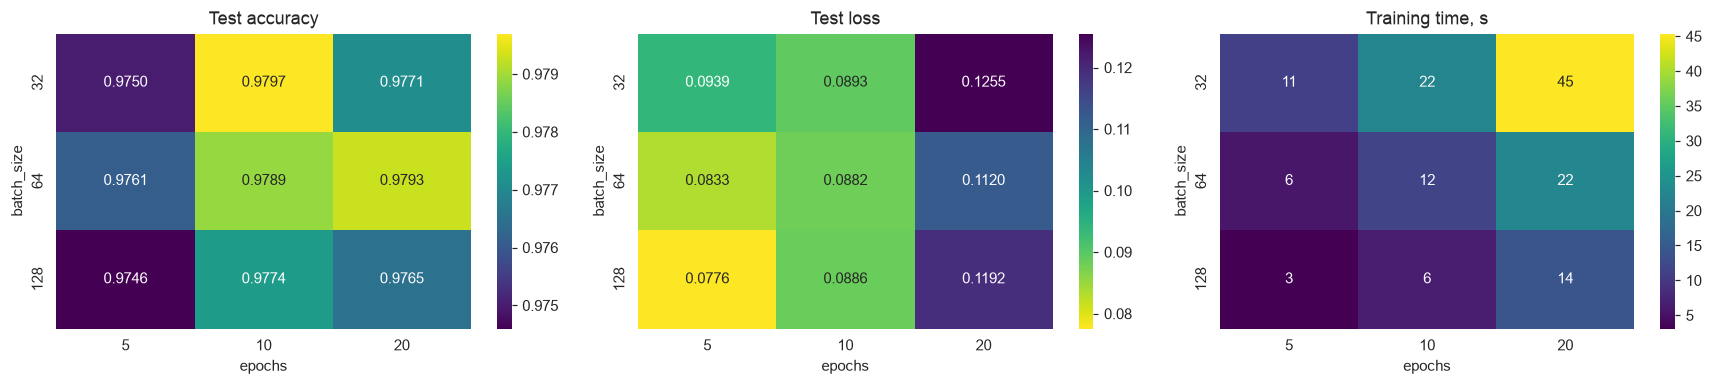

In [186]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, col, title, fmt in zip(axes, ["test_acc", "test_loss", "time_s"],
                               ["Test accuracy", "Test loss", "Training time, s"], [".4f", ".4f", ".0f"]):
    piv = t4_results.pivot(index="batch_size", columns="epochs", values=col)
    sns.heatmap(piv, annot=True, fmt=fmt, cmap="viridis" if col != "test_loss" else "viridis_r", ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.show()

### Кривые обучения (Accuracy / Loss vs эпохи)
Берём 20-эпоховые запуски для каждого batch size (5- и 10-эпоховые запуски с тем же сидом - это их начало).

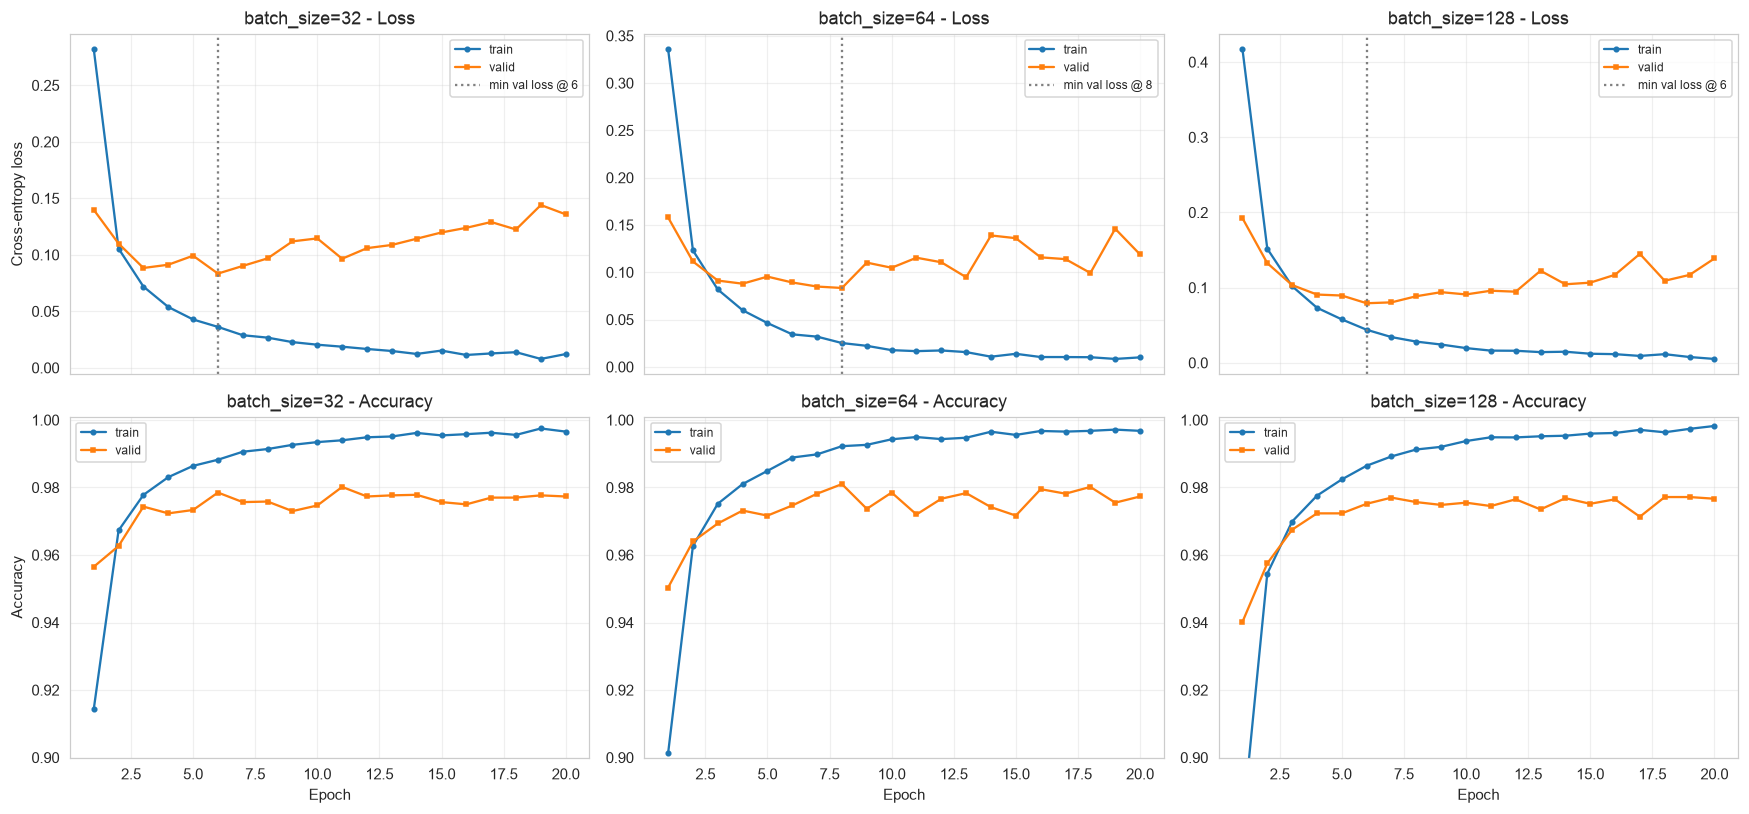

In [187]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for col, bs in enumerate(T4_CFG["batch_grid"]):
    h = t4_runs[(20, bs)][1]; ep = np.arange(1, 21)
    axes[0, col].plot(ep, h["train_loss"], "o-", ms=3, label="train"); axes[0, col].plot(ep, h["val_loss"], "s-", ms=3, label="valid")
    axes[1, col].plot(ep, h["train_acc"], "o-", ms=3, label="train"); axes[1, col].plot(ep, h["val_acc"], "s-", ms=3, label="valid")
    best = int(np.argmin(h["val_loss"])) + 1
    axes[0, col].axvline(best, color="gray", ls=":", label=f"min val loss @ {best}")
    axes[0, col].set_title(f"batch_size={bs} - Loss"); axes[1, col].set_title(f"batch_size={bs} - Accuracy")
    axes[1, col].set_xlabel("Epoch"); axes[1, col].set_ylim(0.9, 1.001)
    for r in range(2): axes[r, col].grid(alpha=0.3); axes[r, col].legend(fontsize=8)
axes[0, 0].set_ylabel("Cross-entropy loss"); axes[1, 0].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

## 4.6 Примеры правильных и неправильных предсказаний

Лучшая модель по test accuracy: epochs=10, batch=32, acc=0.9797


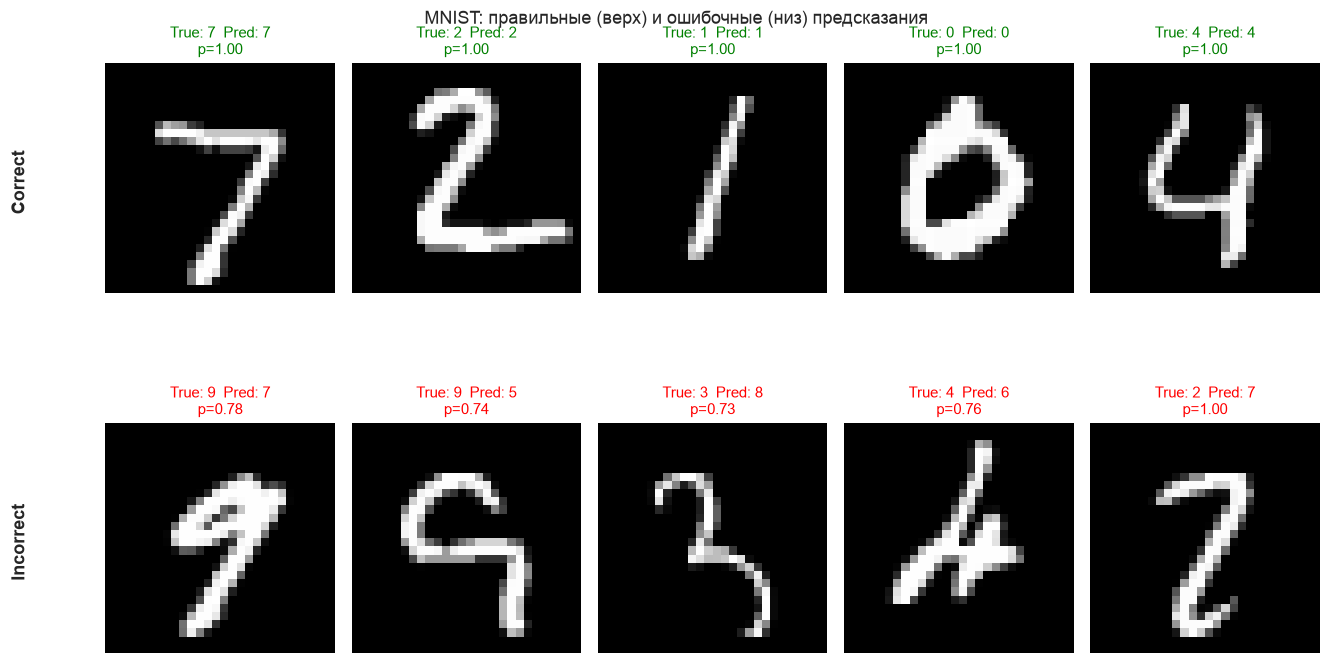

In [188]:
best_row = t4_results.sort_values("test_acc", ascending=False).iloc[0]
best_key = (int(best_row.epochs), int(best_row.batch_size))
best_mlp = t4_runs[best_key][0]; best_mlp.eval()
print(f"Лучшая модель по test accuracy: epochs={best_key[0]}, batch={best_key[1]}, acc={best_row.test_acc:.4f}")

with torch.no_grad():
    probs = torch.softmax(best_mlp(Xm_test), dim=1)       # вот где нужен Softmax
conf, ym_pred = probs.max(1)
correct_idx = torch.where(ym_pred == ym_test)[0][:5]
wrong_idx = torch.where(ym_pred != ym_test)[0][:5]

fig, axes = plt.subplots(2, 5, figsize=(12, 6.2))
for row, (idxs, title) in enumerate([(correct_idx, "Correct"), (wrong_idx, "Incorrect")]):
    for ax, i in zip(axes[row], idxs):
        ax.imshow(Xm_test[i].view(28, 28), cmap="gray"); ax.axis("off")
        ax.set_title(f"True: {ym_test[i].item()}  Pred: {ym_pred[i].item()}\np={conf[i]:.2f}",
                     color="green" if row == 0 else "red", fontsize=10)
    axes[row, 0].text(-12, 14, title, rotation=90, va="center", fontsize=12, fontweight="bold")
plt.suptitle("MNIST: правильные (верх) и ошибочные (низ) предсказания"); plt.tight_layout(); plt.subplots_adjust(hspace=0.45); plt.show()

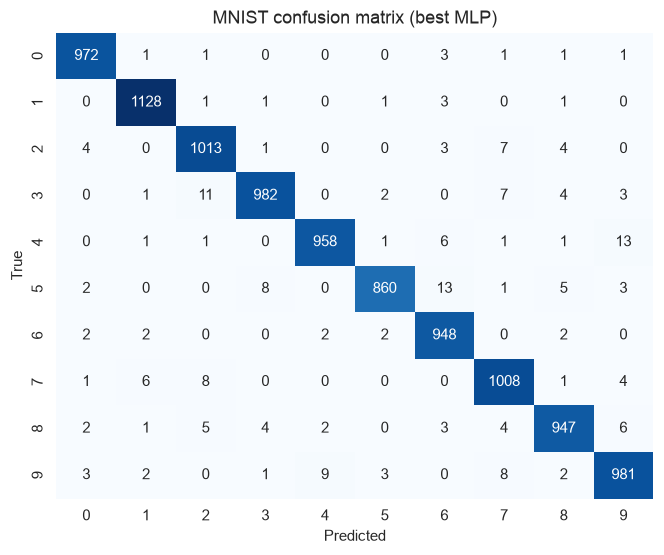

Чаще всего путаются (true → pred: кол-во): 5→6: 13, 4→9: 13, 3→2: 11, 9→4: 9, 9→7: 8, 7→2: 8


,0,1,2,3,4,5,6,7,8,9
accuracy per digit,0.99180,0.99380,0.98160,0.97230,0.97560,0.96410,0.98960,0.98050,0.97230,0.97220


In [189]:
# Какие цифры путаются чаще всего?
cm_m = confusion_matrix(ym_test, ym_pred)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_m, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("MNIST confusion matrix (best MLP)"); plt.show()

per_class_acc = pd.Series(cm_m.diagonal() / cm_m.sum(1), index=range(10), name="accuracy per digit")
off = cm_m.copy(); np.fill_diagonal(off, 0)
top = sorted(((off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j]), reverse=True)[:6]
print("Чаще всего путаются (true → pred: кол-во):", ", ".join(f"{i}→{j}: {n}" for n, i, j in top))
per_class_acc.round(4).to_frame().T

### Интерпретация и выводы по Task 4

**Общий результат.** Все 9 конфигураций дают test accuracy 97.3–98.2%, разница не больше ~0.8 п.п. Лучшая - **20 эпох, batch 128: test accuracy 98.15%**. У неё же максимальная validation accuracy (0.980), так что выбор не «подогнан» под тест.

**Влияние числа эпох.**
- Train loss падает всё время (≈0.05 → ≈0.01), train accuracy доходит до 99.6–99.8%.
- Validation loss достигает минимума рано: на 4-й эпохе при batch 32 и на 8-й при batch 64/128. Потом он **растёт** (до 0.12–0.14), хотя train loss продолжает падать. Это **переобучение**: сеть запоминает train и становится слишком уверенной в своих ошибках.
- Accuracy при этом выходит на плато (~97.5–98%) и даже чуть растёт, потому что accuracy учитывает только argmax, а loss штрафует уверенные ошибки. Test loss тоже ухудшается с эпохами, например при batch 64: 0.077 (5 эп.) → 0.097 (10) → 0.114 (20).
- Итог: после ~5–8 эпох больше обучения почти не даёт пользы, лучше использовать раннюю остановку по validation loss.

**Влияние batch size.**
- **Скорость:** 20 эпох при batch 32 заняли ~94 с, при 64 - ~50 с, при 128 - ~27 с, то есть почти в 3.5 раза быстрее. Большой батч лучше использует векторные вычисления, и шагов оптимизатора меньше (1688 → 422 за эпоху).
- **Шум:** при batch 32 кривые validation loss/accuracy «скачут» сильнее всего, потому что градиент по 32 картинкам шумный. При batch 128 кривые глаже.
- При коротком обучении (5 эпох) у batch 128 чуть ниже train accuracy (98.2% против 98.6%): за то же число эпох сеть сделала в 4 раза меньше шагов.
- **Обобщение:** теоретически большой батч может ухудшать обобщение. Градиент менее шумный, и оптимизатор чаще попадает в «острые» минимумы, которые хуже переносятся на новые данные. В нашем диапазоне (32–128) этого не видно: 128 - всё ещё маленький батч, эффект обычно появляется при размерах в сотни и тысячи.

**Ошибки модели.** Чаще всего путаются 9→4 (11 раз), 5→3 и 4→9 (по 9), 7→2 (7). Это цифры, похожие по начертанию. MLP «разворачивает» картинку в вектор и не учитывает пространственную структуру пикселей, поэтому небрежно написанные цифры для него трудны. Свёрточная сеть (CNN) на MNIST обычно даёт 99%+.

**Самые эффективные настройки:** batch size 64–128 и примерно 8–10 эпох с ранней остановкой по validation loss. Это почти максимальная accuracy при минимальном времени и без переобучения по loss. Если важна только accuracy, лучший результат дала комбинация 20 эпох / batch 128.